In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)

In [3]:
df = pd.read_csv("Mall_Customers.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [10]:
df = df.rename(columns={
    "CustomerID": "ID",
    "Gender": "Genero",
    "Age": "Edad",
    "Annual Income (k$)": "Ingreso_Anual",
    "Spending Score (1-100)": "Puntaje_Gasto"
})
df.head()

,ID,Genero,Edad,Ingreso_Anual,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
print("Valores nulos por columna:\n", df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["ID"].duplicated().sum())

Valores nulos por columna:
 ID               0
Genero           0
Edad             0
Ingreso_Anual    0
Puntaje_Gasto    0
dtype: int64

Filas duplicadas: 0
IDs repetidos: 0


In [12]:
df["Genero"] = df["Genero"].str.strip().str.capitalize()
print("Categorías de género:", df["Genero"].unique())

print("Edades fuera de 18-100:", (~df["Edad"].between(18, 100)).sum())
print("Ingresos negativos:", (df["Ingreso_Anual"] < 0).sum())
print("Puntajes fuera de 1-100:", (~df["Puntaje_Gasto"].between(1, 100)).sum())

Categorías de género: <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
Edades fuera de 18-100: 0
Ingresos negativos: 0
Puntajes fuera de 1-100: 0


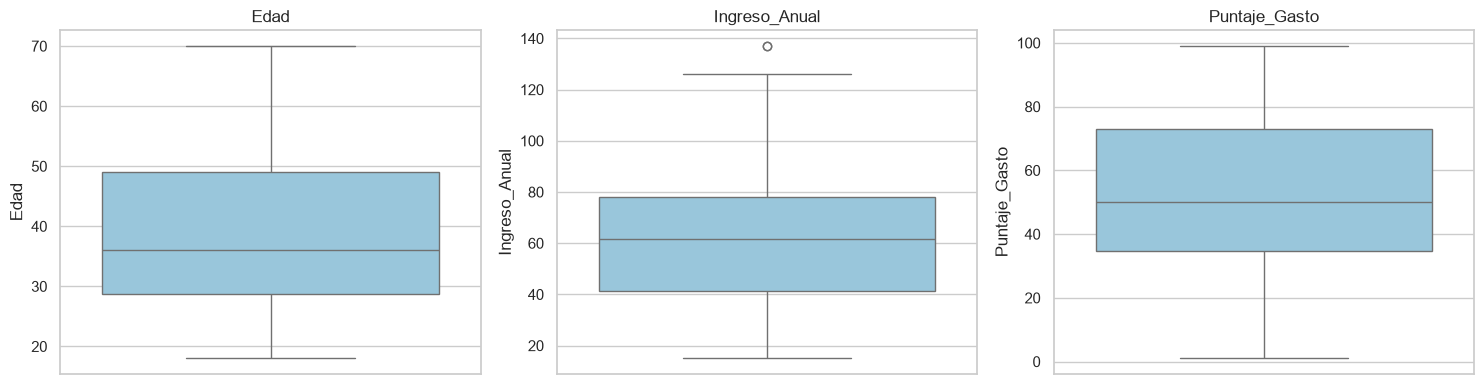

Edad: límites [-1.6, 79.4] -> 0 atípicos
Ingreso_Anual: límites [-13.2, 132.8] -> 2 atípicos
Puntaje_Gasto: límites [-22.6, 130.4] -> 0 atípicos


In [13]:
num_cols = ["Edad", "Ingreso_Anual", "Puntaje_Gasto"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#8ecae6")
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    print(f"{col}: límites [{lim_inf:.1f}, {lim_sup:.1f}] -> {len(atipicos)} atípicos")

In [14]:
df_limpio = df.drop(columns="ID")          # el ID no aporta información de comportamiento
df_limpio["Genero_num"] = df_limpio["Genero"].map({"Male": 0, "Female": 1})

df_limpio.to_csv("clientes_limpio.csv", index=False)
print("Dataset limpio:", df_limpio.shape)
df_limpio.head()

Dataset limpio: (200, 5)


,Genero,Edad,Ingreso_Anual,Puntaje_Gasto,Genero_num
0,Male,19,15,39,0
1,Male,21,15,81,0
2,Female,20,16,6,1
3,Female,23,16,77,1
4,Female,31,17,40,1


In [15]:
# Verificación final de limpieza
print("Duplicados ignorando el ID:", df.drop(columns="ID").duplicated().sum())
print("Nulos en Genero_num (falló el mapeo):", df_limpio["Genero_num"].isnull().sum())
print("\nTipos de datos:\n", df_limpio.dtypes)

# Ver los 2 clientes atípicos
df[df["Ingreso_Anual"] > 132.8]

Duplicados ignorando el ID: 0
Nulos en Genero_num (falló el mapeo): 0

Tipos de datos:
 Genero             str
Edad             int64
Ingreso_Anual    int64
Puntaje_Gasto    int64
Genero_num       int64
dtype: object


,ID,Genero,Edad,Ingreso_Anual,Puntaje_Gasto
198,199,Male,32,137,18
199,200,Male,30,137,83


### Resumen de la limpieza
- Se renombraron las columnas para facilitar su manejo.
- No se encontraron valores nulos.
- No hay filas duplicadas (ni siquiera ignorando el ID) ni IDs repetidos.
- Las categorías de género son consistentes (Male / Female).
- Todos los valores numéricos están dentro de rangos válidos.
- Se detectaron 2 valores atípicos en Ingreso Anual (137k). Se **conservaron** porque
  son clientes reales y no errores de registro, representan solo el 1% de los datos, y
  eliminarlos haría perder información del segmento de mayores ingresos.
- Se eliminó la columna ID porque no aporta información sobre el comportamiento del cliente.
- Se codificó el género numéricamente (Male = 0, Female = 1).

In [16]:
df_limpio.describe().round(2)

,Edad,Ingreso_Anual,Puntaje_Gasto,Genero_num
count,200.00,200.00,200.00,200.00
mean,38.85,60.56,50.20,0.56
std,13.97,26.26,25.82,0.50
min,18.00,15.00,1.00,0.00
25%,28.75,41.50,34.75,0.00
50%,36.00,61.50,50.00,1.00
75%,49.00,78.00,73.00,1.00
max,70.00,137.00,99.00,1.00


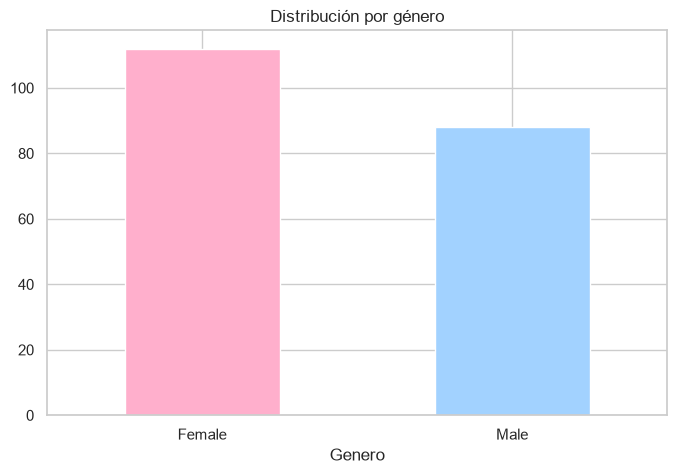

In [17]:
df_limpio["Genero"].value_counts().plot(kind="bar", color=["#ffafcc", "#a2d2ff"])
plt.title("Distribución por género")
plt.xticks(rotation=0)
plt.show()


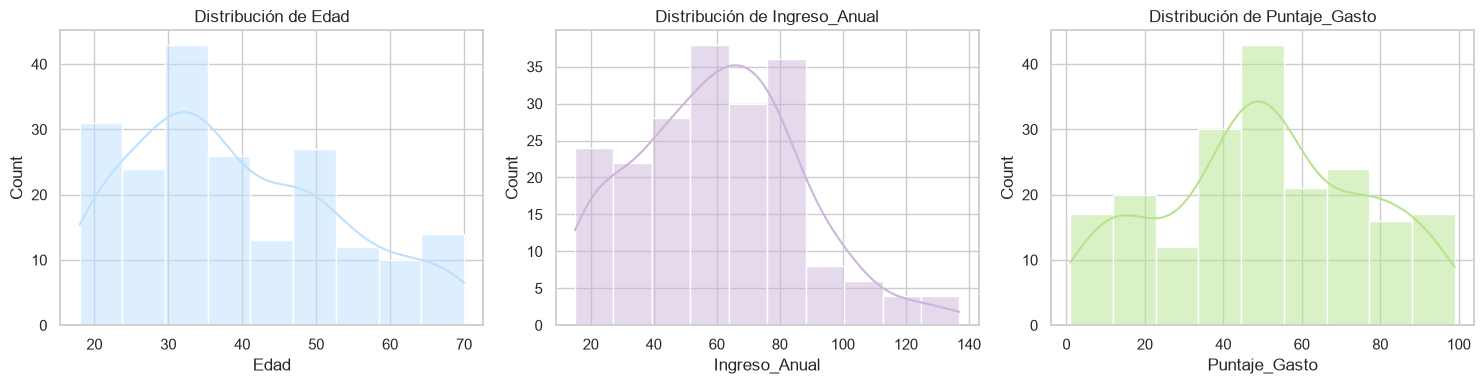

In [18]:
num_cols = ["Edad", "Ingreso_Anual", "Puntaje_Gasto"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colores = ["#bde0fe", "#cdb4db", "#b5e48c"]
for ax, col, c in zip(axes, num_cols, colores):
    sns.histplot(df_limpio[col], kde=True, ax=ax, color=c)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

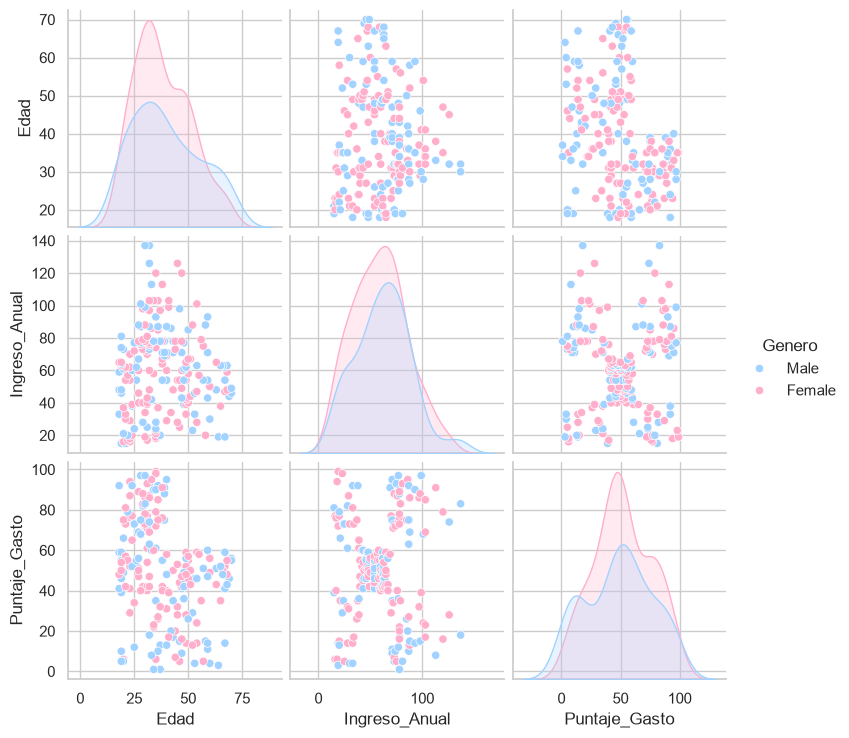

In [19]:
sns.pairplot(df_limpio, vars=num_cols, hue="Genero",
             palette={"Male": "#a2d2ff", "Female": "#ffafcc"})
plt.show()

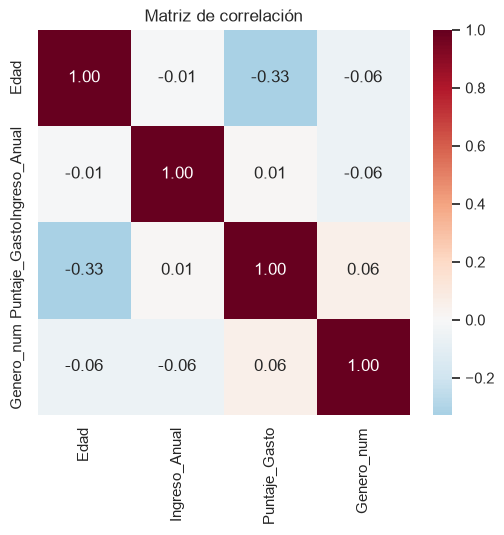

In [20]:
plt.figure(figsize=(6, 5))
sns.heatmap(df_limpio[num_cols + ["Genero_num"]].corr(), annot=True,
            cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Matriz de correlación")
plt.show()

In [21]:
X = df_limpio[["Ingreso_Anual", "Puntaje_Gasto"]]
X.head()

,Ingreso_Anual,Puntaje_Gasto
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**
Ingreso Anual y Puntaje de Gasto. Juntas describen la capacidad económica del cliente y su
comportamiento de compra, que es lo que interesa en marketing. En el gráfico de dispersión
entre ambas se observan aproximadamente 5 grupos bien separados. El género no se usa porque
hombres (88) y mujeres (112) se distribuyen de forma muy similar en todas las variables y su
correlación con las demás es casi nula (±0.06). Usar dos variables permite además visualizar
los clusters en 2D e interpretarlos fácilmente.

**¿Se identifican valores atípicos?**
Sí, solo 2 en Ingreso Anual: dos clientes con ingresos de 137k, por encima del límite superior
del IQR (132.8k). Se conservaron porque son datos reales y válidos, no errores de registro.
Edad y Puntaje de Gasto no presentan atípicos.

**¿Qué tipo de relaciones se observan entre las variables?**
- Ingreso Anual y Puntaje de Gasto tienen correlación lineal casi nula (0.01), pero en el
  diagrama de dispersión forman grupos claros. La relación no es lineal sino por segmentos,
  lo cual es ideal para K-Means.
- Edad y Puntaje de Gasto tienen una correlación negativa moderada (-0.33): los clientes más
  jóvenes tienden a gastar más.
- Edad e Ingreso no están relacionados (-0.01).
- El género no muestra relación relevante con ninguna variable.

# Parte 2 – Preprocesamiento

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled_df.describe().round(2)

,Ingreso_Anual,Puntaje_Gasto
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


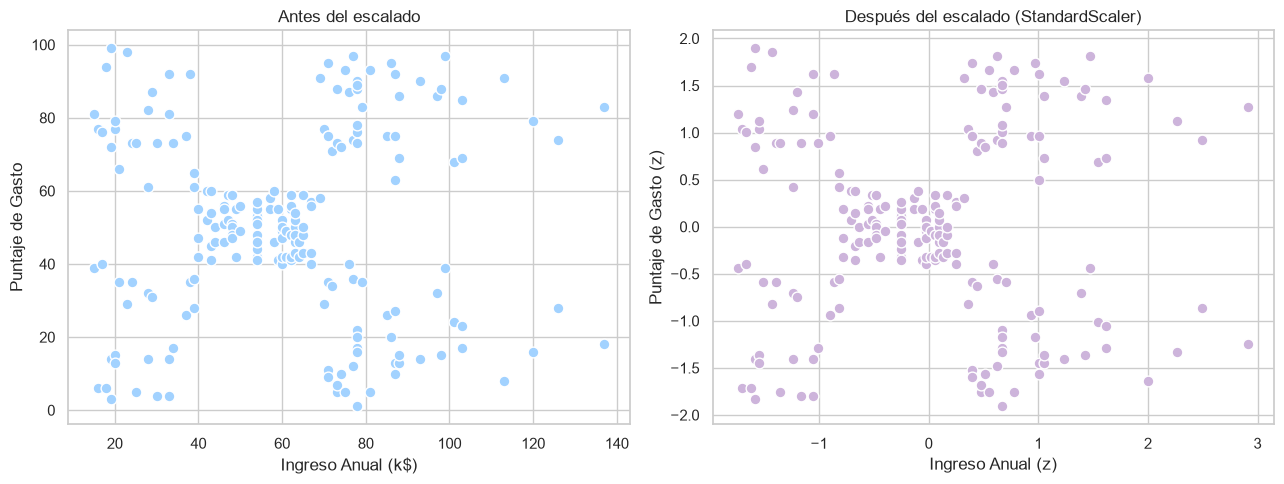

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X["Ingreso_Anual"], X["Puntaje_Gasto"], color="#a2d2ff", edgecolor="white", s=60)
axes[0].set_title("Antes del escalado")
axes[0].set_xlabel("Ingreso Anual (k$)"); axes[0].set_ylabel("Puntaje de Gasto")

axes[1].scatter(X_scaled_df["Ingreso_Anual"], X_scaled_df["Puntaje_Gasto"], color="#cdb4db", edgecolor="white", s=60)
axes[1].set_title("Después del escalado (StandardScaler)")
axes[1].set_xlabel("Ingreso Anual (z)"); axes[1].set_ylabel("Puntaje de Gasto (z)")
plt.tight_layout()
plt.show()

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**
K-Means agrupa usando la distancia euclidiana entre los puntos y los centroides. Si las
variables están en escalas distintas, la de mayor rango domina la distancia y el modelo
prácticamente ignora a las demás. En este dataset el ingreso va de 15 a 137 y el puntaje de
gasto de 1 a 99. StandardScaler transforma cada variable para que tenga media 0 y desviación
estándar 1, así ambas pesan lo mismo en el cálculo de distancias y los clusters reflejan
patrones reales y no diferencias de unidades.

# Parte 3 – Método del Codo


In [24]:
from sklearn.cluster import KMeans

inercias = []
rango_k = range(1, 11)

for k in rango_k:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

pd.DataFrame({"K": list(rango_k), "Inercia (WCSS)": np.round(inercias, 2)})

,K,Inercia (WCSS)
0,1,400.00
1,2,269.69
2,3,157.70
3,4,108.92
4,5,65.57
5,6,55.06
6,7,44.86
7,8,37.23
8,9,32.39
9,10,29.98


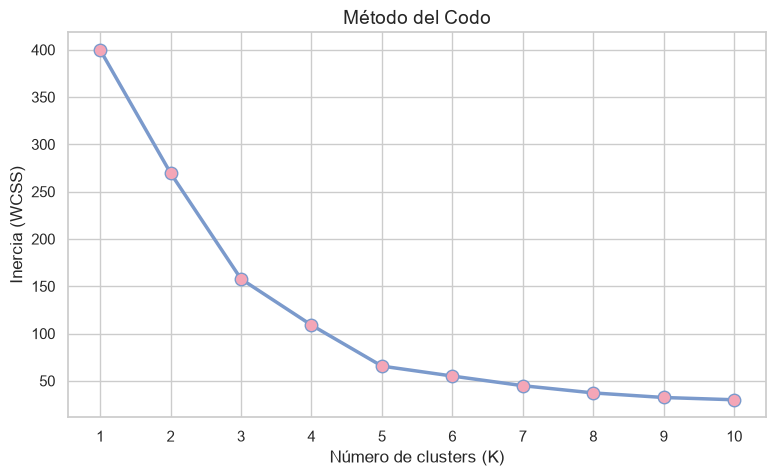

In [25]:
plt.figure(figsize=(9, 5))
plt.plot(rango_k, inercias, marker="o", color="#7b9acc", linewidth=2.5,
         markersize=9, markerfacecolor="#f4a6b7")
plt.title("Método del Codo", fontsize=14)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.xticks(rango_k)
plt.show()

In [26]:
tabla_codo = pd.DataFrame({"K": list(rango_k), "Inercia": np.round(inercias, 2)})
tabla_codo["Reducción absoluta"] = (-tabla_codo["Inercia"].diff()).round(2)
tabla_codo["Reducción %"] = (-tabla_codo["Inercia"].pct_change() * 100).round(1)
tabla_codo

,K,Inercia,Reducción absoluta,Reducción %
0,1,400.00,NaN,NaN
1,2,269.69,130.31,32.6
2,3,157.70,111.99,41.5
3,4,108.92,48.78,30.9
4,5,65.57,43.35,39.8
5,6,55.06,10.51,16.0
6,7,44.86,10.20,18.5
7,8,37.23,7.63,17.0
8,9,32.39,4.84,13.0
9,10,29.98,2.41,7.4


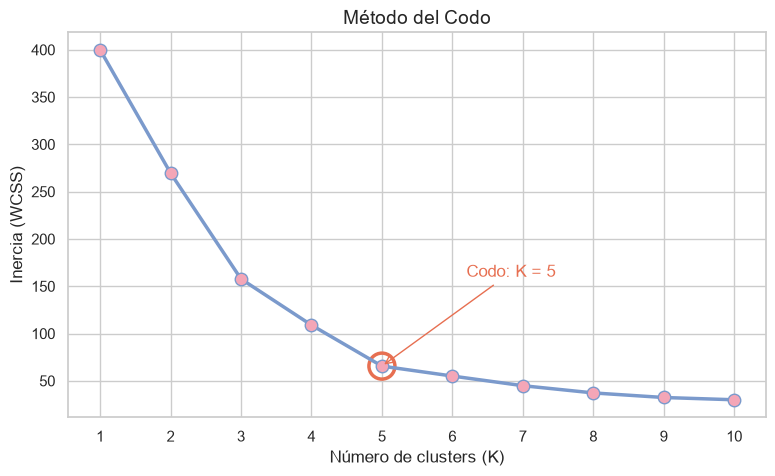

In [27]:
plt.figure(figsize=(9, 5))
plt.plot(rango_k, inercias, marker="o", color="#7b9acc", linewidth=2.5,
         markersize=9, markerfacecolor="#f4a6b7")
plt.scatter(5, inercias[4], s=350, facecolors="none", edgecolors="#e76f51", linewidths=2.5)
plt.annotate("Codo: K = 5", xy=(5, inercias[4]), xytext=(6.2, 160),
             fontsize=12, color="#e76f51",
             arrowprops=dict(arrowstyle="->", color="#e76f51"))
plt.title("Método del Codo", fontsize=14)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.xticks(rango_k)
plt.show()

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**
La inercia (WCSS) es la suma de las distancias al cuadrado entre cada punto y el centroide de
su cluster. Un valor cercano a cero significa que los puntos están muy cerca de su centroide,
es decir, que los clusters son compactos y homogéneos. Sin embargo, la inercia siempre
disminuye al aumentar K y llega a cero cuando cada punto es su propio cluster (K = 200), lo
que no sirve para segmentar. Por eso no se busca el mínimo, sino el punto donde agregar más
clusters deja de mejorar significativamente.

**¿Cómo se identifica el punto óptimo de K?**
Se busca el "codo" de la curva: el punto donde la inercia deja de caer bruscamente y empieza
a disminuir de forma lenta. En este caso, de K = 1 a K = 5 la inercia baja de 400 a 65.57,
con reducciones grandes en cada paso (de K = 4 a K = 5 baja 43.35). A partir de K = 5 las
reducciones son pequeñas (de K = 5 a K = 6 solo baja 10.51). Por lo tanto, **K = 5** es el
número óptimo de clusters según el método del codo.

# Parte 4 – Coeficiente de Silueta

In [29]:
from sklearn.metrics import silhouette_score

siluetas = []
rango_k_sil = range(2, 11)   # la silueta no se puede calcular con K = 1

for k in rango_k_sil:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, etiquetas))

tabla_sil = pd.DataFrame({"K": list(rango_k_sil), "Silueta": np.round(siluetas, 4)})
tabla_sil

,K,Silueta
0,2,0.3213
1,3,0.4666
2,4,0.4939
3,5,0.5547
4,6,0.5399
5,7,0.5281
6,8,0.4552
7,9,0.4571
8,10,0.4432


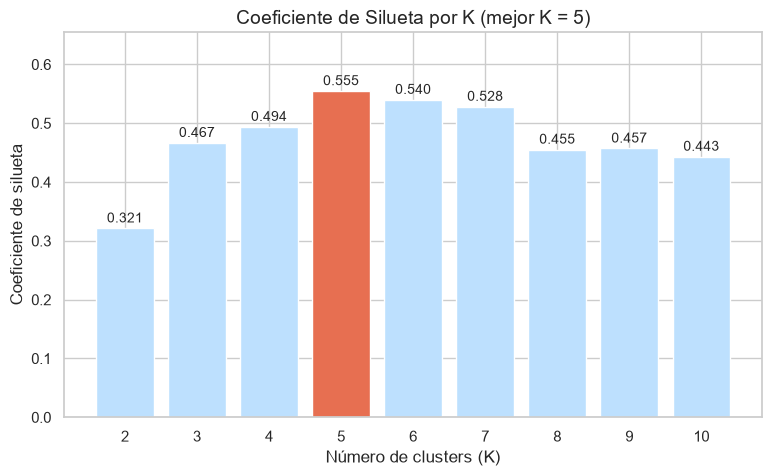

In [30]:
k_mejor = list(rango_k_sil)[np.argmax(siluetas)]
colores_barras = ["#e76f51" if k == k_mejor else "#bde0fe" for k in rango_k_sil]

plt.figure(figsize=(9, 5))
plt.bar(rango_k_sil, siluetas, color=colores_barras, edgecolor="white")
for k, s in zip(rango_k_sil, siluetas):
    plt.text(k, s + 0.01, f"{s:.3f}", ha="center", fontsize=10)
plt.title(f"Coeficiente de Silueta por K (mejor K = {k_mejor})", fontsize=14)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(rango_k_sil)
plt.ylim(0, max(siluetas) + 0.1)
plt.show()

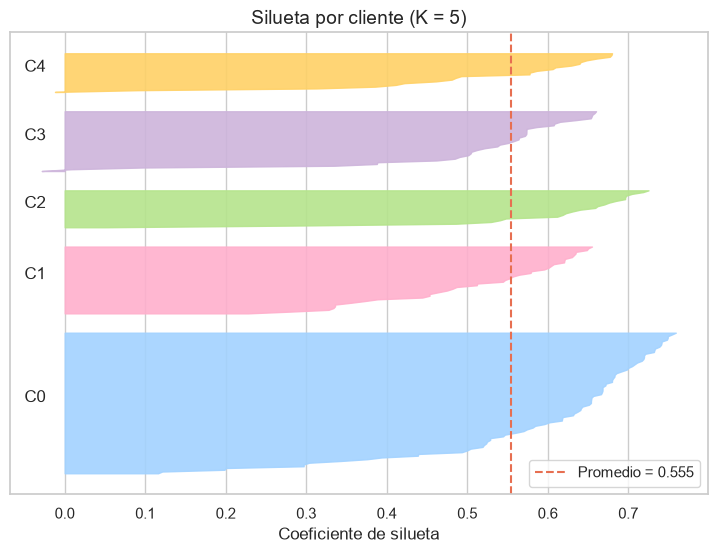

Clientes con silueta negativa (mal asignados): 2


In [31]:
from sklearn.metrics import silhouette_samples

km5 = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
etiquetas5 = km5.fit_predict(X_scaled)
valores_sil = silhouette_samples(X_scaled, etiquetas5)
prom = silhouette_score(X_scaled, etiquetas5)

paleta = ["#a2d2ff", "#ffafcc", "#b5e48c", "#cdb4db", "#ffd166"]
plt.figure(figsize=(9, 6))
y_inf = 10
for i in range(5):
    vals = np.sort(valores_sil[etiquetas5 == i])
    y_sup = y_inf + len(vals)
    plt.fill_betweenx(np.arange(y_inf, y_sup), 0, vals, color=paleta[i], alpha=0.9)
    plt.text(-0.05, y_inf + len(vals) / 2, f"C{i}")
    y_inf = y_sup + 10
plt.axvline(prom, color="#e76f51", linestyle="--", label=f"Promedio = {prom:.3f}")
plt.title("Silueta por cliente (K = 5)", fontsize=14)
plt.xlabel("Coeficiente de silueta")
plt.yticks([])
plt.legend()
plt.show()

print("Clientes con silueta negativa (mal asignados):", (valores_sil < 0).sum())

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**
Mide qué tan bien asignado está cada punto a su cluster, comparando su distancia promedio
con los puntos de su propio cluster (cohesión) frente a su distancia promedio con los puntos
del cluster vecino más cercano (separación). Toma valores entre -1 y 1. El coeficiente
general es el promedio de todos los puntos.

**¿Qué significa un valor cercano a 1?**
Que el punto está muy cerca de los miembros de su cluster y lejos de los demás: clusters
compactos y bien separados, es decir, una segmentación de buena calidad.

**¿Qué implica un valor cercano a 0 o negativo?**
Un valor cercano a 0 indica que el punto está en la frontera entre dos clusters, por lo que
los grupos se solapan. Un valor negativo indica que el punto probablemente fue asignado al
cluster equivocado, porque está más cerca de otro grupo que del suyo.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**
Sí, ambos métodos coinciden en **K = 5**. En el método del codo, la inercia cae bruscamente
hasta K = 5 (de 400 a 65.57) y a partir de ahí las reducciones son pequeñas. En el
coeficiente de silueta, K = 5 obtiene el valor más alto (0.5547), superior a K = 6 (0.5399)
y K = 4 (0.4999). Además, en la gráfica de silueta por cliente los 5 clusters tienen valores
mayormente positivos y solo 2 de 200 clientes (1%) tienen silueta negativa, lo que indica
que casi todos están bien asignados. Que dos métodos distintos (uno basado en la compacidad
y otro en la cohesión y separación) lleguen al mismo resultado da mayor confianza en que
5 es el número adecuado de segmentos.

# Parte 5 – Modelo K-Means

In [32]:
kmeans = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
df_limpio["Cluster"] = kmeans.fit_predict(X_scaled)

print("Clientes por cluster:")
df_limpio["Cluster"].value_counts().sort_index()

Clientes por cluster:


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

In [33]:
centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns
).round(2)
centroides.index.name = "Cluster"
centroides

,Ingreso_Anual,Puntaje_Gasto
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


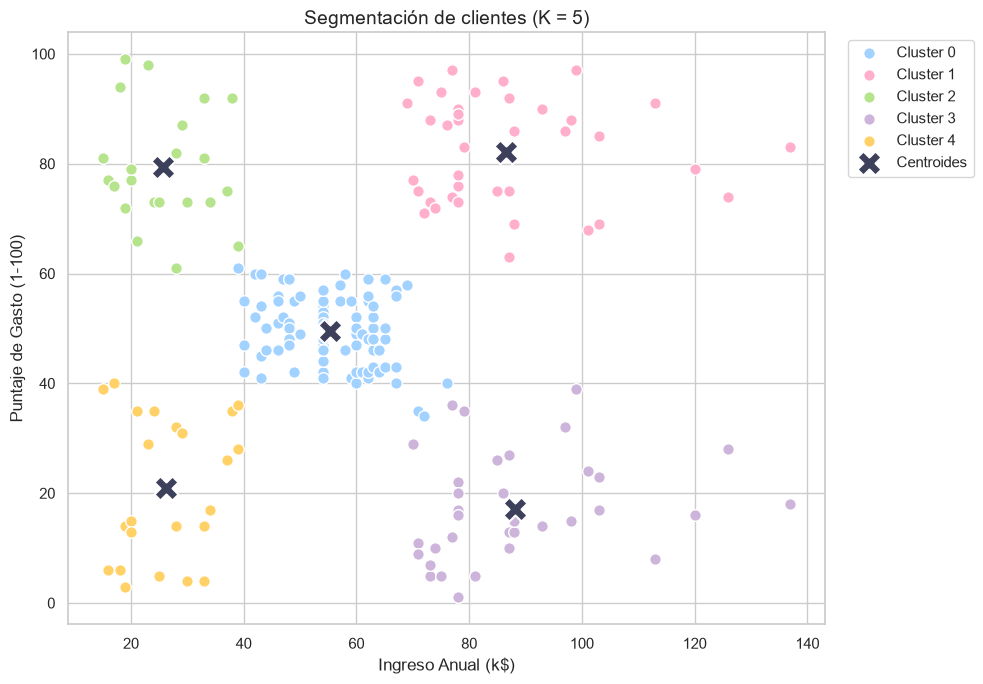

In [34]:
paleta = ["#a2d2ff", "#ffafcc", "#b5e48c", "#cdb4db", "#ffd166"]

plt.figure(figsize=(10, 7))
for i in range(5):
    grupo = df_limpio[df_limpio["Cluster"] == i]
    plt.scatter(grupo["Ingreso_Anual"], grupo["Puntaje_Gasto"], s=70,
                color=paleta[i], edgecolor="white", label=f"Cluster {i}")
plt.scatter(centroides["Ingreso_Anual"], centroides["Puntaje_Gasto"], s=300,
            color="#3d405b", marker="X", edgecolor="white", linewidths=1.5, label="Centroides")
plt.title("Segmentación de clientes (K = 5)", fontsize=14)
plt.xlabel("Ingreso Anual (k$)")
plt.ylabel("Puntaje de Gasto (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [39]:
perfil = df_limpio.groupby("Cluster").agg(
    Clientes=("Edad", "count"),
    Edad_prom=("Edad", "mean"),
    Ingreso_prom=("Ingreso_Anual", "mean"),
    Gasto_prom=("Puntaje_Gasto", "mean"),
    Pct_mujeres=("Genero_num", "mean")
)
perfil["Pct_mujeres"] = perfil["Pct_mujeres"] * 100
perfil = perfil.round(1)
perfil

,Clientes,Edad_prom,Ingreso_prom,Gasto_prom,Pct_mujeres
Cluster,,,,,
0,81,42.7,55.3,49.5,59.3
1,39,32.7,86.5,82.1,53.8
2,22,25.3,25.7,79.4,59.1
3,35,41.1,88.2,17.1,45.7
4,23,45.2,26.3,20.9,60.9


In [36]:
import joblib

joblib.dump(kmeans, "modelo_kmeans.pkl")
joblib.dump(scaler, "scaler.pkl")
df_limpio.to_csv("clientes_segmentados.csv", index=False)
print("Modelo, scaler y datos segmentados guardados correctamente")

Modelo, scaler y datos segmentados guardados correctamente


### Preguntas – Parte 5

**¿Qué representa cada cluster?**
Cada cluster es un grupo de clientes con un comportamiento similar en ingreso y gasto. Su
centroide es el "cliente promedio" del grupo:
- **Cluster 0 (81 clientes):** ingreso medio (≈55k) y gasto medio (≈50). Es el segmento más grande.
- **Cluster 1 (39 clientes):** ingreso alto (≈87k) y gasto alto (≈82). Edad promedio de 33 años.
- **Cluster 2 (22 clientes):** ingreso bajo (≈26k) pero gasto alto (≈79). Son los más jóvenes (≈25 años).
- **Cluster 3 (35 clientes):** ingreso alto (≈88k) pero gasto bajo (≈17).
- **Cluster 4 (23 clientes):** ingreso bajo (≈26k) y gasto bajo (≈21). Son los de mayor edad (≈45 años).

**¿Qué diferencias existen entre los grupos obtenidos?**
La principal diferencia es la combinación entre capacidad económica y disposición a gastar.
Los clusters 1 y 3 tienen ingresos casi iguales (≈87-88k) pero un comportamiento opuesto: el
1 gasta mucho y el 3 muy poco, lo que muestra que el ingreso por sí solo no determina el
gasto. Lo mismo ocurre entre los clusters 2 y 4, ambos con ingresos bajos (≈26k): el 2 gasta
mucho y el 4 poco. La edad también ayuda a explicarlo: los grupos que más gastan (1 y 2) son
los más jóvenes (25-33 años), mientras que los que menos gastan (3 y 4) son mayores
(41-45 años). El género tiene poca influencia: en casi todos los grupos predominan ligeramente las mujeres
(54-61%), excepto en los clientes con potencial (cluster 3), donde hay un poco más de hombres
(54%).

# Parte 6 – Interpretación de Negocio

In [40]:
perfiles = {
    0: "Clientes promedio",
    1: "Clientes de alto valor",
    2: "Clientes impulsivos",
    3: "Clientes con potencial",
    4: "Clientes de bajo valor"
}
df_limpio["Perfil"] = df_limpio["Cluster"].map(perfiles)

perfil["Perfil"] = perfil.index.map(perfiles)
perfil

,Clientes,Edad_prom,Ingreso_prom,Gasto_prom,Pct_mujeres,Perfil
Cluster,,,,,,
0,81,42.7,55.3,49.5,59.3,Clientes promedio
1,39,32.7,86.5,82.1,53.8,Clientes de alto valor
2,22,25.3,25.7,79.4,59.1,Clientes impulsivos
3,35,41.1,88.2,17.1,45.7,Clientes con potencial
4,23,45.2,26.3,20.9,60.9,Clientes de bajo valor


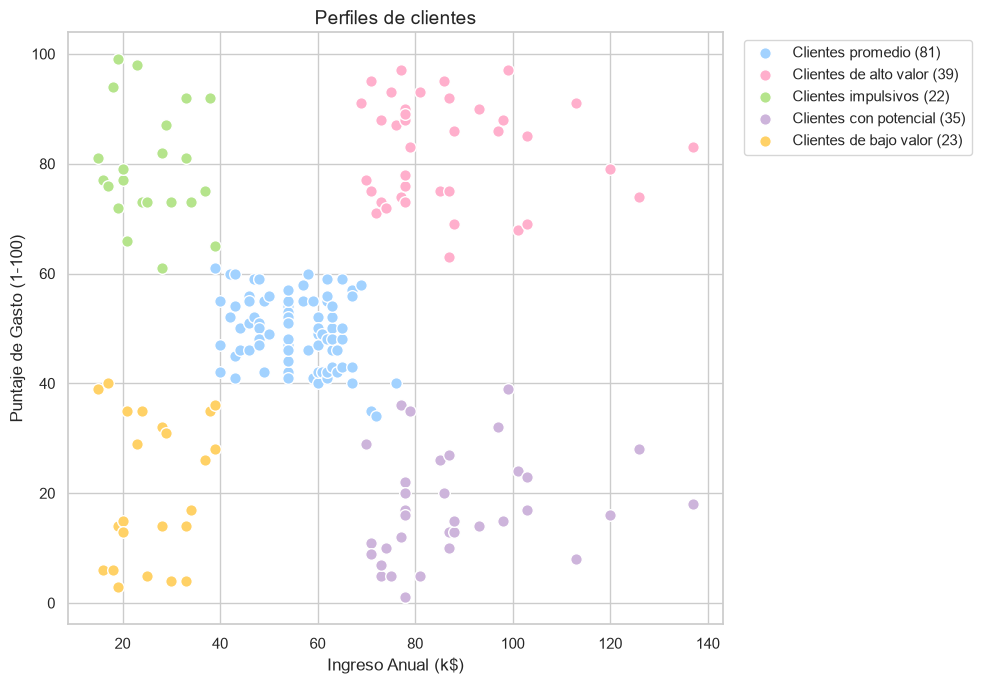

In [41]:
colores_perfil = {
    "Clientes promedio": "#a2d2ff",
    "Clientes de alto valor": "#ffafcc",
    "Clientes impulsivos": "#b5e48c",
    "Clientes con potencial": "#cdb4db",
    "Clientes de bajo valor": "#ffd166"
}

plt.figure(figsize=(10, 7))
for nombre, color in colores_perfil.items():
    g = df_limpio[df_limpio["Perfil"] == nombre]
    plt.scatter(g["Ingreso_Anual"], g["Puntaje_Gasto"], s=70, color=color,
                edgecolor="white", label=f"{nombre} ({len(g)})")
plt.title("Perfiles de clientes", fontsize=14)
plt.xlabel("Ingreso Anual (k$)")
plt.ylabel("Puntaje de Gasto (1-100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [42]:
df_limpio.to_csv("clientes_segmentados.csv", index=False)
joblib.dump(perfiles, "perfiles.pkl")
print("Datos con perfiles guardados")

Datos con perfiles guardados


### Preguntas – Parte 6

**Clasificación de los clusters**
| Cluster | Perfil | Características |
|---|---|---|
| 1 | Clientes de alto valor | Ingreso alto, gasto alto, ~33 años |
| 0 | Clientes promedio | Ingreso medio, gasto medio, ~43 años |
| 4 | Clientes de bajo valor | Ingreso bajo, gasto bajo, ~45 años |
| 3 | Clientes con potencial | Ingreso alto, gasto bajo, ~41 años |
| 2 | Clientes impulsivos | Ingreso bajo, gasto alto, ~25 años |

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**
- **Alto valor:** programas de fidelización VIP, acceso anticipado a lanzamientos, atención
  personalizada y productos premium. El objetivo es retenerlos.
- **Promedio:** promociones por volumen (2x1, combos), programa de puntos y venta cruzada para
  aumentar el ticket promedio poco a poco.
- **Bajo valor:** campañas de bajo costo (correo, redes), descuentos en productos básicos y
  ofertas en temporadas especiales. No conviene invertir mucho presupuesto en ellos.
- **Con potencial:** marketing de calidad y exclusividad, experiencias personalizadas,
  productos de mayor gama y encuestas para entender por qué compran poco. El objetivo es
  convertirlos en clientes de alto valor.
- **Impulsivos:** promociones de tendencia en redes sociales, opciones de pago a cuotas y
  productos de moda a precio accesible, siempre de forma responsable porque gastan por
  encima de su ingreso.

**¿Qué segmento representa mayor oportunidad de crecimiento?**
Los **clientes con potencial (cluster 3)**. Tienen casi el mismo ingreso que los clientes de
alto valor (≈88k frente a ≈87k), pero gastan casi 5 veces menos (17 frente a 82 puntos). Es
decir, tienen capacidad de compra que hoy no se está aprovechando. Además son un grupo
grande (35 clientes, 17.5% del total). Si el centro comercial logra entender sus
necesidades y ofrecerles productos acordes a su nivel económico, podría convertirlos en
clientes de alto valor, lo que generaría el mayor aumento en ventas.